<p style="font-size: 32px; color: red;">Phase 2.1: Exploration (EDA)</p>

In [30]:
# Load the data and check its shape, columns, and types.
# Summarize: central tendency and spread for numeric columns; value counts for categorical
# ones.
# Visualize distributions with histograms and boxplots and note any early patterns.

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statistics as stats
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix
from sklearn.model_selection import train_test_split


df = pd.read_csv('./nfl_combine_2010_to_2023.csv')
df.head()


,Year,Player,Pos,School,Height,Weight,40yd,Vertical,Bench,Broad Jump,3Cone,Shuttle,Drafted,Round,Pick
0,2010,Seyi Ajirotutu,WR,Fresno State,6-3,204.0,4.60,36.0,14.0,115.0,7.22,4.39,False,NaN,NaN
1,2010,Rahim Alem,DE,LSU,6-3,251.0,4.75,30.5,NaN,106.0,7.54,4.80,False,NaN,NaN
2,2010,Charles Alexander,DT,LSU,6-4,300.0,5.40,NaN,NaN,NaN,NaN,NaN,False,NaN,NaN
3,2010,Danario Alexander,WR,Missouri,6-5,215.0,4.62,NaN,NaN,NaN,NaN,NaN,False,NaN,NaN
4,2010,Nate Allen,S,South Florida,6-0,207.0,4.50,NaN,16.0,NaN,NaN,NaN,True,2.0,37.0


In [31]:
# Describing the shape, data types, and columns

print(df.shape)
print()
df.info()
combine_cols = ["Year", "Player", "Pos", "School", "Height", "Weight", "40yd", "Vertical", "Bench", "Broad Jump", "3Cone", "Shuttle", "Drafted", "Round", "Pick"]


(4741, 15)

<class 'pandas.DataFrame'>
RangeIndex: 4741 entries, 0 to 4740
Data columns (total 15 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Year        4741 non-null   int64  
 1   Player      4741 non-null   str    
 2   Pos         4741 non-null   str    
 3   School      4741 non-null   str    
 4   Height      4712 non-null   str    
 5   Weight      4717 non-null   float64
 6   40yd        4194 non-null   float64
 7   Vertical    3731 non-null   float64
 8   Bench       3166 non-null   float64
 9   Broad Jump  3671 non-null   float64
 10  3Cone       2794 non-null   float64
 11  Shuttle     2909 non-null   float64
 12  Drafted     4741 non-null   bool   
 13  Round       3008 non-null   float64
 14  Pick        3008 non-null   float64
dtypes: bool(1), float64(9), int64(1), str(4)
memory usage: 523.3 KB


Phase 2.1.2 Central Tendency, Spreads, and Value Counts

In [32]:
print("-----------------------------------CENTRAL TENDANCY---------------------------------")
print()
summary = df.drop(columns ='Year').describe()
print(summary)
print()
print("-----------------------------------------STD----------------------------------------")
print()
std = df.std(numeric_only=True)
print("Standard Deviation of Numeric Cols")
print(std)
print()
print("-----------------------------------------VAR----------------------------------------")
print()
print("Variance of Numeric Cols")
var = df.var(numeric_only=True)
print(var)

-----------------------------------CENTRAL TENDANCY---------------------------------

            Weight         40yd     Vertical        Bench   Broad Jump  \
count  4717.000000  4194.000000  3731.000000  3166.000000  3671.000000   
mean    241.683909     4.761068    32.926776    20.194251   115.855625   
std      45.384582     0.301064     4.205529     6.432676     9.290842   
min     144.000000     4.220000    17.500000     2.000000    82.000000   
25%     204.000000     4.530000    30.000000    15.000000   110.000000   
50%     231.000000     4.670000    33.000000    20.000000   117.000000   
75%     277.000000     4.950000    36.000000    24.000000   122.000000   
max     384.000000     6.000000    46.500000    49.000000   147.000000   

             3Cone      Shuttle        Round         Pick  
count  2794.000000  2909.000000  3008.000000  3008.000000  
mean      7.251933     4.415895     3.840093   115.872340  
std       0.405234     0.262608     1.915932    70.726114  
min    

In [33]:
# Value Counts For Categorical Values

target_cols = ['Year', 'Player', 'Pos', 'School']

for col in target_cols:
    print(f"------{col}--------")
    print(df[col].value_counts())

------Year--------
Year
2021    464
2020    337
2018    336
2019    336
2014    333
2013    332
2016    332
2011    329
2017    327
2010    326
2012    324
2022    324
2015    322
2023    319
Name: count, dtype: int64
------Player--------
Player
Chris Brown        3
Josh Johnson       3
Chris Jones        3
Anthony Johnson    3
Charles Brown      2
                  ..
Darnell Wright     1
Rejzohn Wright     1
Luke Wypler        1
Bryce Young        1
Cameron Young      1
Name: count, Length: 4700, dtype: int64
------Pos--------
Pos
WR      670
CB      491
RB      426
OT      307
S       306
DT      285
TE      266
DE      261
QB      238
OLB     217
OG      207
LB      179
OL      141
ILB     134
DL      120
C       100
EDGE    100
DB       83
P        81
K        65
FB       42
LS       22
Name: count, dtype: int64
------School--------
School
Alabama                                 144
LSU                                     131
Georgia                                 114
Florida    

2.1.3 Histograms and Boxplots

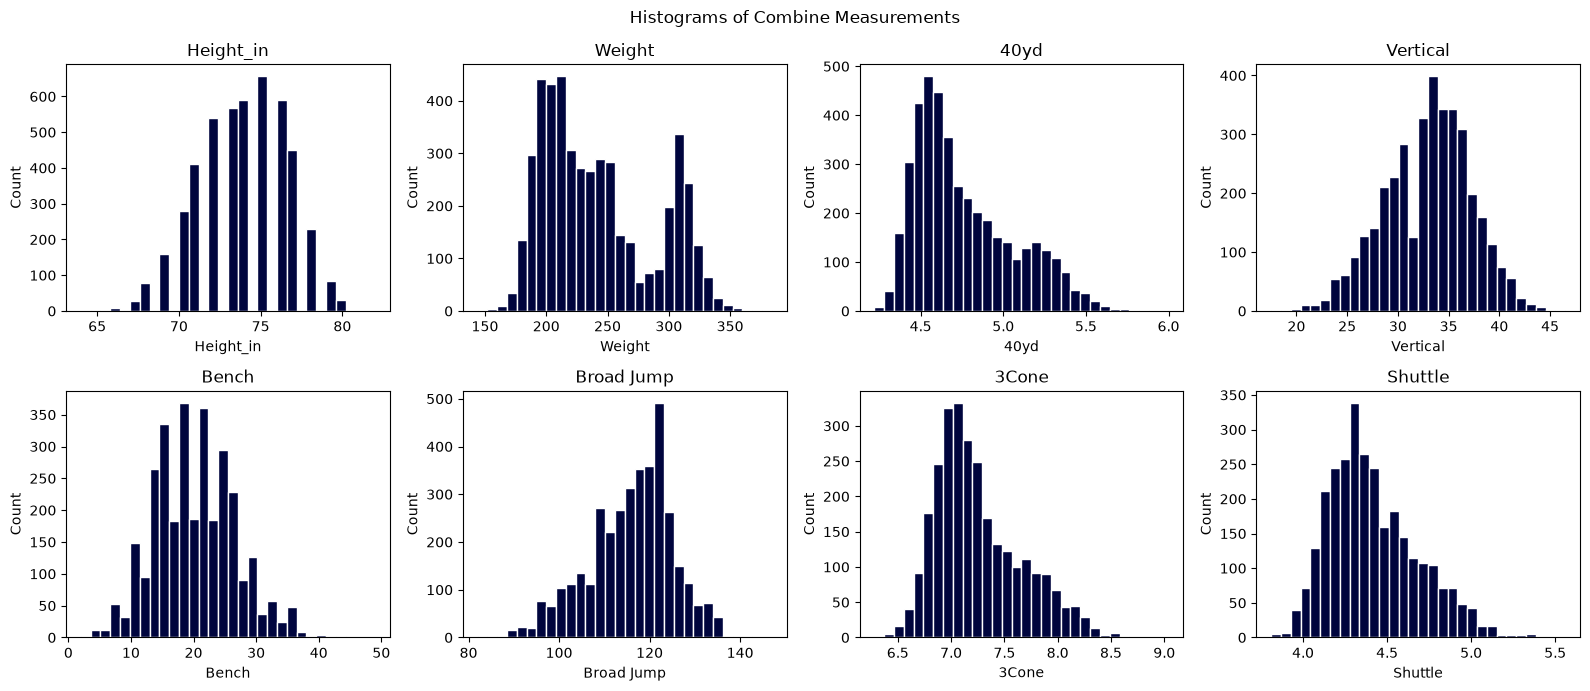

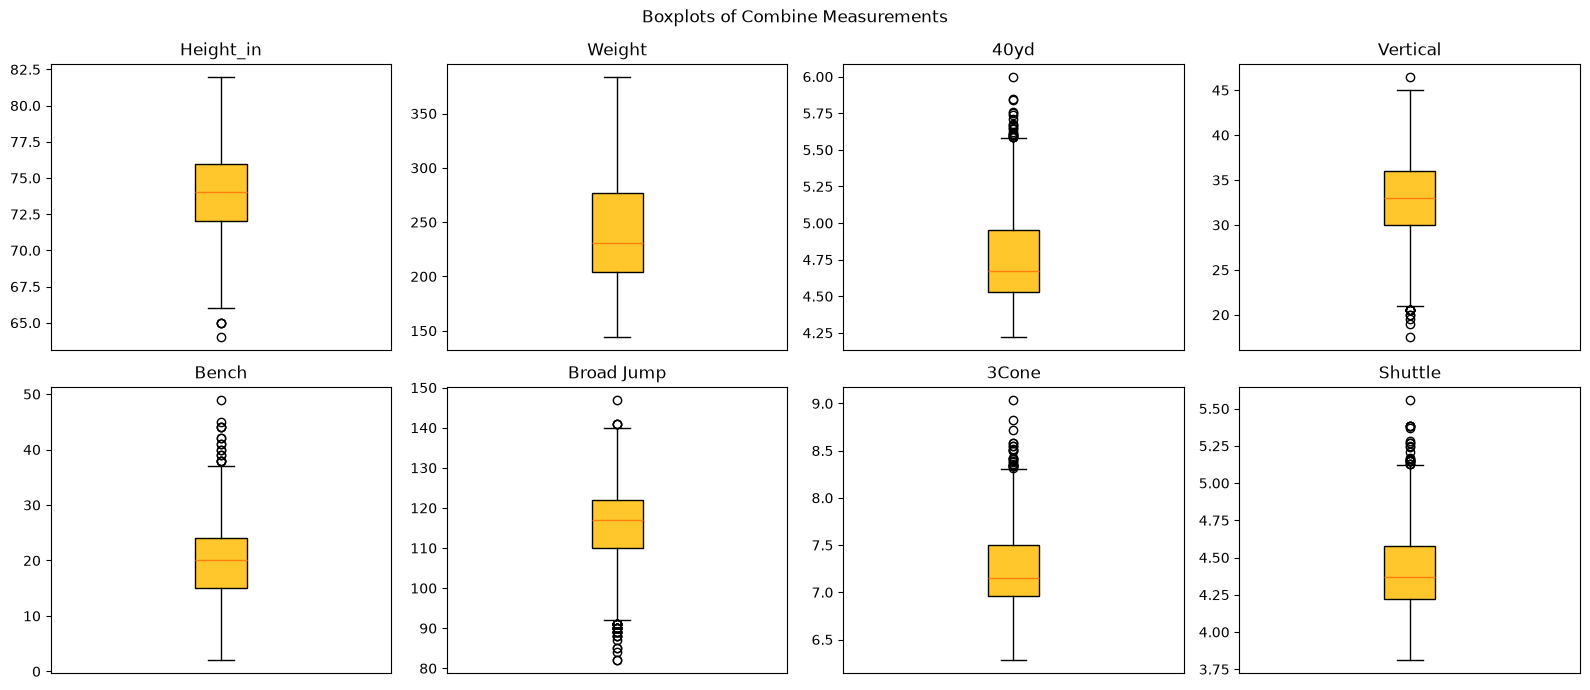

In [34]:
# Convert Height to inches
def height_to_inches(h):
    try:
        ft, inch = str(h).split("-")
        return int(ft) * 12 + int(inch)
    except ValueError:
        return None

df["Height_in"] = df["Height"].apply(height_to_inches)

cols = ["Height_in", "Weight", "40yd", "Vertical", "Bench",
        "Broad Jump", "3Cone", "Shuttle"]
# Histograms
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flat, cols):
    ax.hist(df[col].dropna(), bins=30, color="#00053E", edgecolor="white")
    ax.set_title(col)
    ax.set_xlabel(col); ax.set_ylabel("Count")
plt.suptitle("Histograms of Combine Measurements")
plt.tight_layout()
plt.show()

# Boxplots
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for ax, col in zip(axes.flat, cols):
    ax.boxplot(df[col].dropna(), patch_artist=True,
               boxprops=dict(facecolor="#FFC72C"))
    ax.set_title(col)
    ax.set_xticks([])
plt.suptitle("Boxplots of Combine Measurements")
plt.tight_layout()
plt.show()


We found out that we can't properly display Height due to its original format (e.g. 6-3). Instead, we had to convert that column to where it will measure in inches (6-3 converts to 75 inches). This makes the histogram and box plot look a lot cleaner for that specific column. We also had to drop the column Year in the Central Tendency because year isn't a value that we are trying to quantify or average compared to the other columns.

<p style="font-size: 32px; color: red;">Phase 2.2: Preprocessing</p>

2.2.1 Handle Missing Values

In [35]:
#check for missing values
print(df.isna().sum())

#fix missing values
target_cols = ['Height', 'Weight', '40yd', 'Vertical', 'Bench', 'Broad Jump', '3Cone', 'Shuttle', 'Height_in']

df[target_cols] = df[target_cols].fillna("N/A")

undrafted = ['Round', 'Pick']
df[undrafted] = df[undrafted].fillna("UD")

Year             0
Player           0
Pos              0
School           0
Height          29
Weight          24
40yd           547
Vertical      1010
Bench         1575
Broad Jump    1070
3Cone         1947
Shuttle       1832
Drafted          0
Round         1733
Pick          1733
Height_in       29
dtype: int64


2.2.2 Remove duplicates and fix inconsistent labels.

In [36]:
# No duplicates or inconsistent labels found

#Check for duplicates
print("Duplicate rows:", df.duplicated().sum())

# Display duplicate rows
duplicates = df[df.duplicated(keep=False)]
print(duplicates)

#Check for inconsistent labels
categorical_cols = df.select_dtypes(include=["object", "category"]).columns

for col in categorical_cols:
    print(f"\n{col}:")
    print(df[col].unique())

Duplicate rows: 0
Empty DataFrame
Columns: [Year, Player, Pos, School, Height, Weight, 40yd, Vertical, Bench, Broad Jump, 3Cone, Shuttle, Drafted, Round, Pick, Height_in]
Index: []

Player:
<StringArray>
[   'Seyi Ajirotutu',        'Rahim Alem', 'Charles Alexander',
 'Danario Alexander',        'Nate Allen',      'Tyson Alualu',
    'Jonathon Amaya',       'Pat Angerer',    'Lucien Antoine',
     'Javier Arenas',
 ...
      'Tyree Wilson',       'Dee Winters', 'Devon Witherspoon',
      'Colby Wooden',    'Darnell Wright',    'Rejzohn Wright',
       'Luke Wypler',       'Bryce Young',       'Byron Young',
     'Cameron Young']
Length: 4700, dtype: str

Pos:
<StringArray>
[  'WR',   'DE',   'DT',    'S',  'ILB',   'CB',   'OG',   'RB',  'OLB',
    'P',   'QB',   'OT',    'C',   'TE',   'FB',   'LS',    'K',   'DL',
 'EDGE',   'LB',   'DB',   'OL']
Length: 22, dtype: str

School:
<StringArray>
[                        'Fresno State',
                                  'LSU',
           

C:\Users\aphil\AppData\Local\Temp\ipykernel_32892\1438281487.py:11: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical_cols = df.select_dtypes(include=["object", "category"]).columns


2.2.3 Deal with outliers

In [37]:

#No outliers detected

numeric_cols = df.select_dtypes(include=np.number).columns

for col in numeric_cols:
    data = df[col].dropna()

    # Z-score
    mean, std = data.mean(), data.std()
    z = (data - mean) / std
    z_outliers = data[z.abs() > 3]

    # IQR
    Q1 = data.quantile(0.25)
    Q3 = data.quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    iqr_outliers = data[(data < lower) | (data > upper)]

    print(f"\n{col}")
    print(f"Z-score flagged {len(z_outliers)} outliers")
    print(f"IQR flagged {len(iqr_outliers)} outliers")


Year
Z-score flagged 0 outliers
IQR flagged 0 outliers


2.2.4 Encode categorical columns

In [38]:
#encoded the drafted and position columns for our future analysis
columns = ['Drafted', 'Pos']

#store in copy
df_encoded = pd.get_dummies(df, columns=columns, dtype=int)

print(df_encoded.dtypes)
print(df_encoded.shape)
print(df_encoded.head())

Year              int64
Player              str
School              str
Height              str
Weight           object
40yd             object
Vertical         object
Bench            object
Broad Jump       object
3Cone            object
Shuttle          object
Round            object
Pick             object
Height_in        object
Drafted_False     int64
Drafted_True      int64
Pos_C             int64
Pos_CB            int64
Pos_DB            int64
Pos_DE            int64
Pos_DL            int64
Pos_DT            int64
Pos_EDGE          int64
Pos_FB            int64
Pos_ILB           int64
Pos_K             int64
Pos_LB            int64
Pos_LS            int64
Pos_OG            int64
Pos_OL            int64
Pos_OLB           int64
Pos_OT            int64
Pos_P             int64
Pos_QB            int64
Pos_RB            int64
Pos_S             int64
Pos_TE            int64
Pos_WR            int64
dtype: object
(4741, 38)
   Year             Player         School Height Weight  40yd V

<p style="font-size: 32px; color: red;">Phase 2.3: Analysis</p>

QUESTION 1: Do physical measurements determine if a player gets drafted?

Players before: 4741 | Players with complete data: 2024

Players per position group:
Pos_Group
OL    403
DB    372
DL    357
WR    308
LB    235
RB    211
TE    125
QB      7
Name: count, dtype: int64

Q1 Results by Position Group
Position  Players  Drafted %  Accuracy  Not Drafted Recall
      DB      372       65.9      0.56                0.46
      DL      357       72.5      0.72                0.21
      LB      235       68.9      0.68                0.30
      OL      403       67.2      0.60                0.21
      QB        7       14.3      0.50                1.00
      RB      211       57.3      0.58                0.17
      TE      125       67.2      0.59                0.86
      WR      308       55.5      0.51                0.75

Height vs Weight Importance by Position Group
    Height_in  Weight
DB       0.30    0.70
DL       0.39    0.61
LB       0.18    0.82
OL       0.47    0.53
QB       0.00    0.00
RB       0.15    0.85
TE       0.56    0.44
WR       0.23  

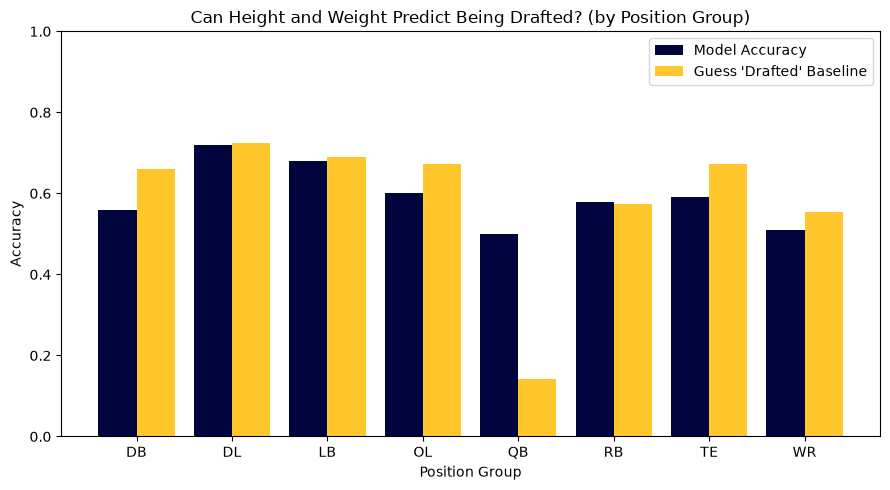

In [48]:
# QUESTION 1: Do physical measurements determine if a player gets drafted? (by position group)
from sklearn.metrics import recall_score

# 1. Keep only players with every combine stat filled in (copy, so df_encoded keeps its 'N/A' values)
df_complete = df_encoded.copy()
stat_cols = ["Height_in", "Weight", "40yd", "Vertical", "Bench", "Broad Jump", "3Cone", "Shuttle"]

for col in stat_cols:
    df_complete[col] = pd.to_numeric(df_complete[col], errors="coerce")

df_complete = df_complete.dropna(subset=stat_cols)
print("Players before:", len(df_encoded), "| Players with complete data:", len(df_complete))

# 2. Group the 22 positions into 8 position groups (K, P, LS left out)
pos_groups = {"QB": "QB", "RB": "RB", "FB": "RB", "WR": "WR", "TE": "TE",
              "OT": "OL", "OG": "OL", "C": "OL", "OL": "OL",
              "DE": "DL", "DT": "DL", "DL": "DL", "EDGE": "DL",
              "ILB": "LB", "OLB": "LB", "LB": "LB",
              "CB": "DB", "S": "DB", "DB": "DB"}

# df_encoded no longer has Pos, so pull it from df using the same rows
df_complete["Pos_Group"] = df.loc[df_complete.index, "Pos"].map(pos_groups)
df_pos = df_complete.dropna(subset=["Pos_Group"])
print("\nPlayers per position group:")
print(df_pos["Pos_Group"].value_counts())

# 3. Train a separate decision tree for each position group
q1_results = []
q1_importance = {}

for group in sorted(df_pos["Pos_Group"].unique()):
    data = df_pos[df_pos["Pos_Group"] == group]
    X = data[["Height_in", "Weight"]]   # physical measurements only
    y = data["Drafted_True"]            # 1 = drafted, 0 = not drafted

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.25, random_state=42
    )

    model = DecisionTreeClassifier(max_depth=3, random_state=42, class_weight="balanced")
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    q1_results.append({
        "Position": group,
        "Players": len(data),
        "Drafted %": round(y.mean() * 100, 1),
        "Accuracy": round(accuracy_score(y_test, y_pred), 2),
        "Not Drafted Recall": round(recall_score(y_test, y_pred, pos_label=0, zero_division=0), 2),
    })
    q1_importance[group] = pd.Series(model.feature_importances_, index=X.columns)

q1_results = pd.DataFrame(q1_results)
q1_importance = pd.DataFrame(q1_importance).T.round(2)

# 4. Show the results
print("\nQ1 Results by Position Group")
print(q1_results.to_string(index=False))
print("\nHeight vs Weight Importance by Position Group")
print(q1_importance)

# 5. Chart: accuracy vs the baseline of guessing "drafted" for everyone
x = np.arange(len(q1_results))
plt.figure(figsize=(9, 5))
plt.bar(x - 0.2, q1_results["Accuracy"], width=0.4, color="#00053E", label="Model Accuracy")
plt.bar(x + 0.2, q1_results["Drafted %"] / 100, width=0.4, color="#FFC72C", label="Guess 'Drafted' Baseline")
plt.xticks(x, q1_results["Position"])
plt.title("Can Height and Weight Predict Being Drafted? (by Position Group)")
plt.xlabel("Position Group")
plt.ylabel("Accuracy")
plt.ylim(0, 1)
plt.legend()
plt.tight_layout()
plt.savefig("q1_by_position.png")
plt.show()

# 6. Save for the dashboard
q1_results.to_csv("q1_by_position.csv", index=False)
q1_importance.to_csv("q1_importance_by_position.csv")

Question 1: Do physical measurements determine if a player gets drafted?

Technique: We used classification (a decision tree) because “drafted” is a yes/no outcome. We trained a separate tree for each position group so height and weight are compared only among players with similar body types.

Answer: No. Height and weight alone do not reliably determine whether a player gets drafted. No position group’s model beat simply guessing “drafted” for every player by more than about one point. For DB the model scored 56% against a 66% baseline, for OL 60% against 67%, and for TE 59% against 67%. Where size mattered at all, weight was more important than height for every group except TE.

QUESTION 2: Which combine stats are the best predictors of whether a player gets drafted?

Q2 Results by Position Group
Position  Players  Drafted %  Accuracy  Not Drafted Recall
      DB      372       65.9      0.54                0.46
      DL      357       72.5      0.58                0.54
      LB      235       68.9      0.66                0.39
      OL      403       67.2      0.68                0.47
      QB        7       14.3      0.50                1.00
      RB      211       57.3      0.70                0.79
      TE      125       67.2      0.62                0.71
      WR      308       55.5      0.74                0.59

Feature Importance by Position Group
    Height_in  Weight  40yd  Vertical  Bench  Broad Jump  3Cone  Shuttle
DB       0.10    0.07  0.38      0.06   0.06        0.04   0.29     0.00
DL       0.00    0.29  0.34      0.04   0.09        0.09   0.00     0.14
LB       0.00    0.26  0.48      0.00   0.00        0.00   0.13     0.13
OL       0.18    0.00  0.23      0.19   0.25        0.00   0.00     0.15
QB       0.00    0.00  0.00      0.00

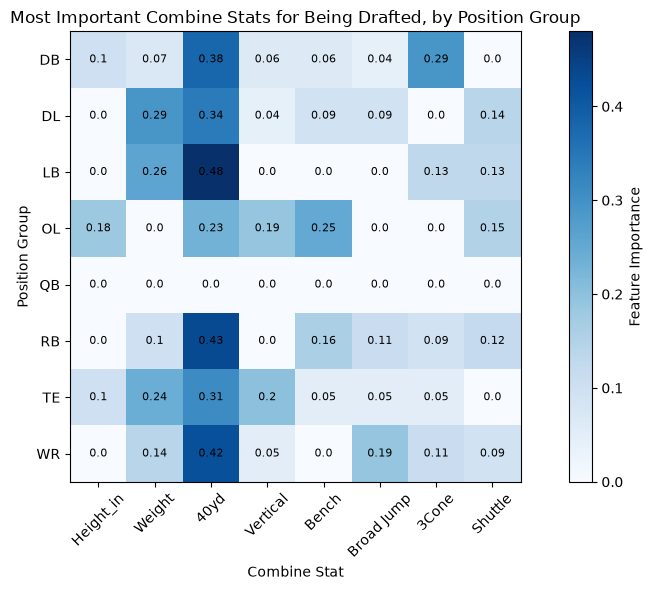

In [49]:
# QUESTION 2: Which combine stats are the best predictors of whether a player gets drafted? (by position group)

# 1. Train a separate decision tree for each position group using all 8 combine stats
q2_results = []
q2_importance = {}

for group in sorted(df_pos["Pos_Group"].unique()):
    data = df_pos[df_pos["Pos_Group"] == group]
    X = data[stat_cols]          # all 8 combine stats
    y = data["Drafted_True"]     # 1 = drafted, 0 = not drafted

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.25, random_state=42
    )

    model = DecisionTreeClassifier(max_depth=4, random_state=42, class_weight="balanced")
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    q2_results.append({
        "Position": group,
        "Players": len(data),
        "Drafted %": round(y.mean() * 100, 1),
        "Accuracy": round(accuracy_score(y_test, y_pred), 2),
        "Not Drafted Recall": round(recall_score(y_test, y_pred, pos_label=0, zero_division=0), 2),
    })
    q2_importance[group] = pd.Series(model.feature_importances_, index=stat_cols)

q2_results = pd.DataFrame(q2_results)
q2_importance = pd.DataFrame(q2_importance).T.round(2)

# 2. Show the results
print("Q2 Results by Position Group")
print(q2_results.to_string(index=False))
print("\nFeature Importance by Position Group")
print(q2_importance)

# 3. Top stat for each position group
print("\nMost important stat for each position group:")
print(q2_importance.idxmax(axis=1))

# 4. Compare Q1 (size only) vs Q2 (all stats)
compare = pd.DataFrame({
    "Position": q2_results["Position"],
    "Q1 Accuracy": q1_results["Accuracy"],
    "Q2 Accuracy": q2_results["Accuracy"],
    "Q1 Not Drafted Recall": q1_results["Not Drafted Recall"],
    "Q2 Not Drafted Recall": q2_results["Not Drafted Recall"],
})
print("\nQ1 vs Q2 Comparison")
print(compare.to_string(index=False))

# 5. Heatmap: which stat matters most for each position group
plt.figure(figsize=(10, 6))
plt.imshow(q2_importance, cmap="Blues")
plt.colorbar(label="Feature Importance")
plt.xticks(range(len(q2_importance.columns)), q2_importance.columns, rotation=45)
plt.yticks(range(len(q2_importance.index)), q2_importance.index)
for i in range(len(q2_importance.index)):
    for j in range(len(q2_importance.columns)):
        plt.text(j, i, q2_importance.iloc[i, j], ha="center", va="center", fontsize=8)
plt.title("Most Important Combine Stats for Being Drafted, by Position Group")
plt.xlabel("Combine Stat")
plt.ylabel("Position Group")
plt.tight_layout()
plt.savefig("q2_importance_by_position.png")
plt.show()

# 6. Save for the dashboard
q2_results.to_csv("q2_by_position.csv", index=False)
q2_importance.to_csv("q2_importance_by_position.csv")
compare.to_csv("q1_vs_q2_comparison.csv", index=False)

Question 2: Which combine stats are the best predictors of whether a player gets drafted?

Technique: We used classification again, now with all eight combine stats, because the outcome is still drafted yes/no. The decision tree’s feature importance directly ranks which stats best predict being drafted.

Answer: The 40-yard dash is the best predictor. It was the most important stat for 6 of the 7 position groups (DB, DL, LB, RB, TE and WR), and bench press mattered most for offensive linemen. Adding the drills improved predictions most for skill positions:

RB: accuracy rose from 58% to 70%, and undrafted players caught rose from 17% to 79%.
WR: accuracy rose from 51% to 74%, beating the 56% baseline.

Drill results, especially speed, predict being drafted better than size does.

QUESTION 3: Can a player’s position group be predicted from his combine results?


Accuracy: 0.66
Random guessing would get about: 0.12

Classification Report:
              precision    recall  f1-score   support

          DB       0.64      0.59      0.61        91
          DL       0.72      0.70      0.71       102
          LB       0.63      0.70      0.66        60
          OL       0.85      0.87      0.86        98
          QB       0.00      0.00      0.00         1
          RB       0.57      0.63      0.60        51
          TE       0.51      0.59      0.55        32
          WR       0.52      0.46      0.49        70

    accuracy                           0.66       505
   macro avg       0.55      0.57      0.56       505
weighted avg       0.66      0.66      0.66       505


Feature Importance:
Weight        0.689553
Height_in     0.200893
Bench         0.037716
40yd          0.035469
Vertical      0.016064
Shuttle       0.010127
3Cone         0.005613
Broad Jump    0.004564
dtype: float64


c:\Users\aphil\miniconda3\envs\analytics\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\aphil\miniconda3\envs\analytics\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\aphil\miniconda3\envs\analytics\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is

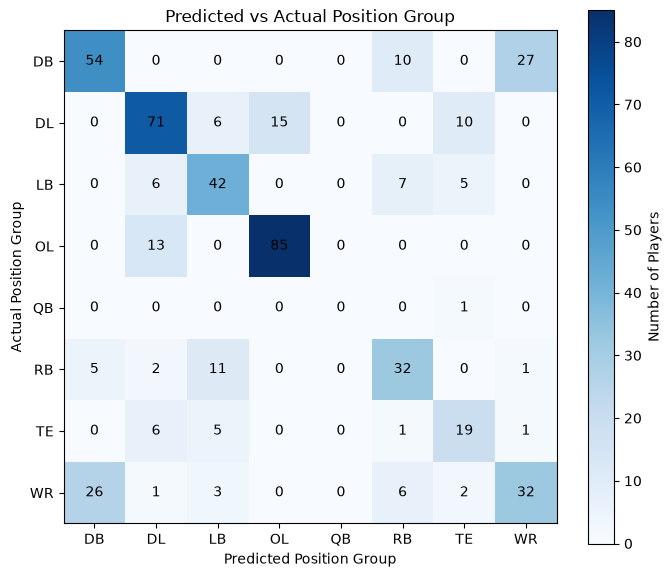

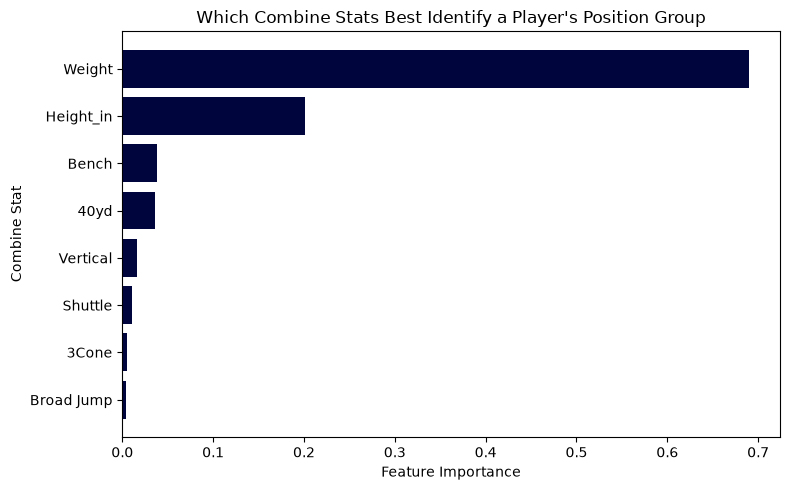

c:\Users\aphil\miniconda3\envs\analytics\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\aphil\miniconda3\envs\analytics\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is", result.shape[0])
c:\Users\aphil\miniconda3\envs\analytics\Lib\site-packages\sklearn\metrics\_classification.py:1879: UndefinedMetricWarning: Precision is ill-defined and being set to 0.0 in labels with no predicted samples. Use `zero_division` parameter to control this behavior.
  _warn_prf(average, modifier, f"{metric.capitalize()} is

In [50]:
# QUESTION 3: Can a player's position group be predicted from his combine results?

# 1. Features and target
X3 = df_pos[stat_cols]        # all 8 combine stats
y3 = df_pos["Pos_Group"]      # QB, RB, WR, TE, OL, DL, LB, DB

# 2. Split into training (75%) and testing (25%) sets
X3_train, X3_test, y3_train, y3_test = train_test_split(
    X3, y3, test_size=0.25, random_state=42
)

# 3. Train the decision tree (multi-class: 8 possible answers)
model3 = DecisionTreeClassifier(max_depth=6, random_state=42)
model3.fit(X3_train, y3_train)

# 4. Predict and evaluate
y3_pred = model3.predict(X3_test)
print(f"Accuracy: {accuracy_score(y3_test, y3_pred):.2f}")
print(f"Random guessing would get about: {1 / y3.nunique():.2f}")
print("\nClassification Report:")
print(classification_report(y3_test, y3_pred))

# 5. Which stats help most to tell positions apart
importance3 = pd.Series(model3.feature_importances_, index=stat_cols).sort_values()
print("\nFeature Importance:")
print(importance3.sort_values(ascending=False))

# 6. Confusion matrix heatmap: which position groups get mixed up
labels = sorted(y3.unique())
cm3 = confusion_matrix(y3_test, y3_pred, labels=labels)

plt.figure(figsize=(7, 6))
plt.imshow(cm3, cmap="Blues")
plt.colorbar(label="Number of Players")
plt.xticks(range(len(labels)), labels)
plt.yticks(range(len(labels)), labels)
for i in range(len(labels)):
    for j in range(len(labels)):
        plt.text(j, i, cm3[i, j], ha="center", va="center")
plt.title("Predicted vs Actual Position Group")
plt.xlabel("Predicted Position Group")
plt.ylabel("Actual Position Group")
plt.tight_layout()
plt.savefig("q3_confusion_matrix.png")
plt.show()

# 7. Feature importance chart
plt.figure(figsize=(8, 5))
plt.barh(importance3.index, importance3.values, color="#00053E")
plt.title("Which Combine Stats Best Identify a Player's Position Group")
plt.xlabel("Feature Importance")
plt.ylabel("Combine Stat")
plt.tight_layout()
plt.savefig("q3_feature_importance.png")
plt.show()

# 8. Save for the dashboard
q3_results = pd.DataFrame(classification_report(y3_test, y3_pred, output_dict=True)).T.round(2)
q3_results.to_csv("q3_results.csv")
importance3.sort_values(ascending=False).to_csv("q3_feature_importance.csv")

Question 3: Can a player’s position group be predicted from his combine results?

Technique: We used multi-class classification because position group is a category with several possible values. The model’s job is to sort each player into the correct group based on his combine results.

Answer: Yes. The model predicted position group with 66% accuracy, compared with about 12% for random guessing across 8 groups. Offensive linemen were easiest to identify (87% recall), followed by DL and LB (70%). Wide receivers (46%) and tight ends (59%) were hardest because their body types overlap with other groups. Weight (69% importance) and height (20%) did most of the work. So size can’t predict being drafted, but it does identify a player’s position.